# 02. Modelagem e avaliação

**Projeto N3 · Turma 8NA · Equipe 10**

**Pergunta:** *dado o que a coordenação sabe sobre um aluno num certo momento, qual a chance de ele evadir?*

**Estratégia de avaliação**

1. **Divisão treino/teste estratificada (80/20):** 3.539 alunos para treino e 885 para teste. O teste só é usado **uma vez**, no fim.
2. **Validação cruzada estratificada de 5 folds** no treino, para comparar modelos e ajustar hiperparâmetros.
3. **Métricas:**
   - **PR-AUC** (principal): resume precisão e recall para a classe "evadiu" sem depender de limiar, e é mais informativa que a ROC-AUC quando a classe positiva é minoria (Saito & Rehmsmeier, 2015).
   - ROC-AUC, recall, precisão e F1.
4. **Limiar de decisão** escolhido maximizando o **F2** nas previsões *fora da amostra* do treino (nunca no teste).

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.precision", 3)

CORES = {"Evadiu": "#d1495b", "Matriculado": "#edae49", "Formado": "#00798c"}
ORDEM = ["Evadiu", "Matriculado", "Formado"]
PASTA_FIGURAS = RAIZ / "reports" / "figuras"
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)


def salvar(fig, nome):
    fig.savefig(PASTA_FIGURAS / nome, dpi=120, bbox_inches="tight")

import warnings

from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_val_score
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay,
                             RocCurveDisplay, classification_report, precision_score, recall_score)

from src.dados import CENARIOS, CURSOS, carregar_dados, todas_colunas_do_cenario
from src.modelo import (calcular_metricas, comparar_modelos, criar_pipeline, dividir_dados,
                        escolher_limiar, validacao_cruzada)
from src.prever import ler_exemplo, prever_evasao
from src.treinar import montar_artefato, treinar_modelo_final

warnings.filterwarnings("ignore", category=UserWarning)

df = carregar_dados()
treino, teste = dividir_dados(df)
print(f"Treino: {len(treino)} alunos ({treino['evadiu'].mean():.1%} evadiram)")
print(f"Teste:  {len(teste)} alunos ({teste['evadiu'].mean():.1%} evadiram)")

Treino: 3539 alunos (32.1% evadiram)
Teste:  885 alunos (32.1% evadiram)


## 1. Cenários e modelos comparados

**Cenários: em que momento a previsão é feita?** Usar dados do futuro deixaria a avaliação otimista demais e inútil na prática. Por isso cada cenário só usa o que já se sabe naquele momento:

| Cenário | Atributos | Tempo para agir |
|---|---|---|
| Na matrícula | perfil, família, ingresso, financeiro, macroeconomia | o curso inteiro |
| Fim do 1º semestre | + desempenho no 1º semestre | do 2º semestre em diante |
| Fim do 2º semestre | + desempenho no 2º semestre | do 2º ano em diante |

**Modelos**

- **Baseline:** prevê sempre a proporção de evasão do treino. É o piso que qualquer modelo precisa superar.
- **Regressão Logística:** linear, interpretável, referência clássica.
- **Random Forest:** média de muitas árvores (*bagging*), robusta e capta não-linearidades.
- **Gradient Boosting** (`HistGradientBoostingClassifier`): árvores em sequência, cada uma corrigindo os erros da anterior. Costuma ser o mais forte em dados tabulares.

In [2]:
comparacao = comparar_modelos(treino)
tabela = comparacao.pivot(index="modelo", columns="cenario", values="pr_auc")[list(CENARIOS)]
tabela.columns = [CENARIOS[c]["titulo"] for c in tabela.columns]
print("PR-AUC média na validação cruzada (5 folds)")
tabela.round(3)

PR-AUC média na validação cruzada (5 folds)


,Na matrícula,Fim do 1º semestre,Fim do 2º semestre
modelo,,,
Baseline (proporção),0.321,0.321,0.321
Gradient Boosting,0.747,0.873,0.891
Random Forest,0.741,0.858,0.885
Regressão Logística,0.744,0.866,0.891


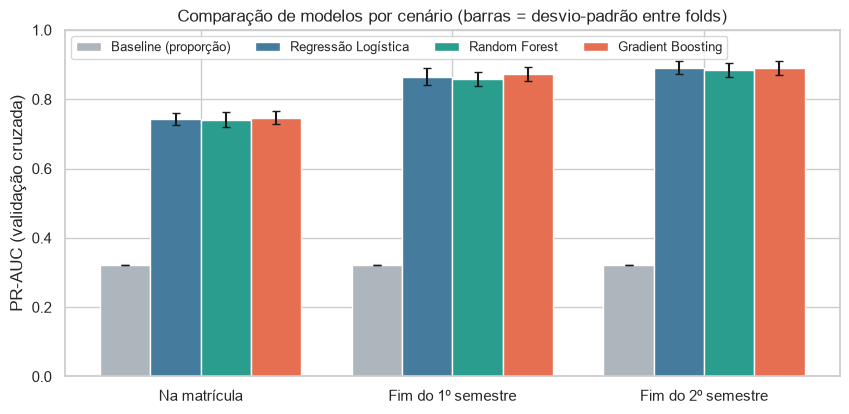

,cenario,modelo,roc_auc,pr_auc,f1,recall,precisao
0,matricula,Baseline (proporção),0.500,0.321,0.000,0.000,0.000
1,matricula,Regressão Logística,0.825,0.744,0.618,0.529,0.744
2,matricula,Random Forest,0.823,0.741,0.598,0.480,0.795
3,matricula,Gradient Boosting,0.825,0.747,0.619,0.534,0.737
4,1_semestre,Baseline (proporção),0.500,0.321,0.000,0.000,0.000
5,1_semestre,Regressão Logística,0.906,0.866,0.766,0.705,0.839
6,1_semestre,Random Forest,0.903,0.858,0.757,0.685,0.847
7,1_semestre,Gradient Boosting,0.911,0.873,0.772,0.722,0.830
8,2_semestre,Baseline (proporção),0.500,0.321,0.000,0.000,0.000
9,2_semestre,Regressão Logística,0.924,0.891,0.796,0.746,0.855


In [3]:
fig, ax = plt.subplots(figsize=(10, 4.5))
modelos = comparacao["modelo"].unique()
largura = 0.2
cores_modelos = ["#adb5bd", "#457b9d", "#2a9d8f", "#e76f51"]
for i, (modelo, cor) in enumerate(zip(modelos, cores_modelos)):
    dados_modelo = comparacao[comparacao["modelo"] == modelo].set_index("cenario").loc[list(CENARIOS)]
    posicoes = np.arange(len(CENARIOS)) + (i - 1.5) * largura
    ax.bar(posicoes, dados_modelo["pr_auc"], largura, yerr=dados_modelo["pr_auc_dp"],
           label=modelo, color=cor, capsize=3)
ax.set_xticks(np.arange(len(CENARIOS)), [CENARIOS[c]["titulo"] for c in CENARIOS])
ax.set_ylabel("PR-AUC (validação cruzada)")
ax.set_ylim(0, 1)
ax.set_title("Comparação de modelos por cenário (barras = desvio-padrão entre folds)")
ax.legend(loc="upper left", ncols=4, fontsize=9)
salvar(fig, "07_comparacao_modelos.png")
plt.show()
comparacao[["cenario", "modelo", "roc_auc", "pr_auc", "f1", "recall", "precisao"]].round(3)

**Leitura dos resultados**

- Todos os modelos superam com folga o baseline (PR-AUC 0,32).
- **O momento da previsão importa mais que o algoritmo.** A PR-AUC sobe de cerca de 0,75 na matrícula para 0,87 no fim do 1º semestre e 0,89 no fim do 2º. Dentro de um mesmo cenário, a diferença entre os três algoritmos é de no máximo 0,015, dentro do desvio-padrão entre os folds.
- Do 1º para o 2º semestre o ganho é pequeno (+0,02) e custa **um semestre inteiro a menos** para intervir.
- A Regressão Logística fica praticamente empatada com o Gradient Boosting. Isso indica que boa parte da relação entre os atributos e a evasão é simples. Uma instituição que exija um modelo totalmente explicável poderia usar a regressão perdendo muito pouco.

## 2. Sensibilidade aos dados financeiros

Como "mensalidades em dia" e "devedor" podem ter sido medidos depois da matrícula (ver notebook 01), treinamos o Gradient Boosting **sem esses dois atributos** para ver quanto o desempenho depende deles.

In [4]:
FINANCEIROS = ("mensalidades_em_dia", "devedor")
linhas = []
for nome_cenario in ["matricula", "1_semestre"]:
    X = treino[todas_colunas_do_cenario(nome_cenario)]
    for rotulo, excluir in [("com financeiros", ()), ("sem financeiros", FINANCEIROS)]:
        pipeline = criar_pipeline("Gradient Boosting", nome_cenario, excluir=excluir)
        pr_auc = cross_val_score(pipeline, X, treino["evadiu"], cv=validacao_cruzada(),
                                 scoring="average_precision", n_jobs=-1).mean()
        linhas.append({"cenário": CENARIOS[nome_cenario]["titulo"], "atributos": rotulo, "PR-AUC": pr_auc})
pd.DataFrame(linhas).pivot(index="cenário", columns="atributos", values="PR-AUC").round(3)

atributos,com financeiros,sem financeiros
cenário,,
Fim do 1º semestre,0.873,0.834
Na matrícula,0.747,0.620


Sem os atributos financeiros, a PR-AUC cai **de 0,747 para 0,620 na matrícula**, mas só **de 0,873 para 0,834 no fim do 1º semestre**.

- **Na matrícula**, o modelo depende bastante das mensalidades. Se esse dado for registrado depois do ingresso, o resultado desse cenário está otimista. Isso entra nas limitações.
- **No fim do 1º semestre**, o desempenho acadêmico carrega a maior parte do sinal, e o modelo continua bom mesmo sem dados financeiros. É mais um motivo para escolher esse cenário.

## 3. Modelo final: Gradient Boosting no cenário "fim do 1º semestre"

Escolhemos esse cenário por equilíbrio: ele já tem o sinal forte do desempenho acadêmico e ainda deixa o restante do curso para agir. O Gradient Boosting teve a maior PR-AUC nele. Os hiperparâmetros foram ajustados por busca em grade (*grid search*) com validação cruzada:

- `learning_rate` ∈ {0,03; 0,1}
- `max_leaf_nodes` ∈ {7, 15, 31}
- `max_iter` ∈ {200, 400}

São 12 combinações × 5 folds = 60 treinos.

In [5]:
NOME_CENARIO, NOME_MODELO = "1_semestre", "Gradient Boosting"
resultado = treinar_modelo_final(treino, teste, NOME_CENARIO, NOME_MODELO)
print("Melhores hiperparâmetros:", resultado["melhores_parametros"])
print(f"PR-AUC na validação cruzada: {resultado['pr_auc_cv']:.3f}")

Melhores hiperparâmetros: {'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 7}
PR-AUC na validação cruzada: 0.875


## 4. Escolha do limiar de decisão

O modelo devolve uma **probabilidade**. Para decidir quem entra na lista de acompanhamento, precisamos de um **limiar**. O padrão 0,5 não é necessariamente o melhor, porque os dois erros têm custos diferentes:

- **Falso negativo** (aluno que vai evadir e não é sinalizado): perde-se a chance de intervir. É o erro **mais caro**.
- **Falso positivo** (aluno sinalizado que não evadiria): custa uma conversa com o tutor ou um e-mail de acompanhamento.

Por isso maximizamos o **F2**, que dá peso 2 ao recall. A escolha usa as probabilidades *fora da amostra* do treino (`cross_val_predict`), sem olhar o teste.

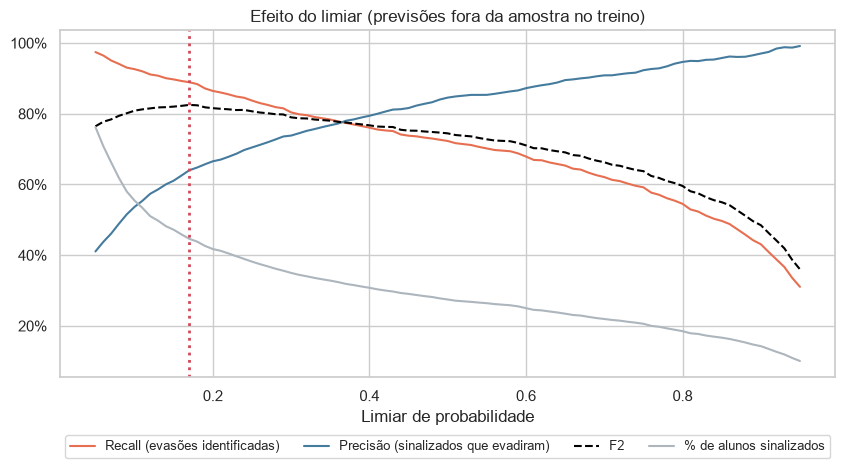

,precisao,recall,f1,f2,verdadeiros_positivos,falsos_positivos,falsos_negativos
"0,50 (padrão)",0.846,0.723,0.780,0.745,822.0,150.0,315.0
"0,43 (máx. F1)",0.812,0.751,0.780,0.762,854.0,198.0,283.0
"0,17 (máx. F2, escolhido)",0.640,0.889,0.744,0.825,1011.0,568.0,126.0


In [6]:
y_oof, p_oof = treino["evadiu"].to_numpy(), resultado["prob_oof"]
curva = resultado["curva_limiar"].copy()
curva["precisao"] = [precision_score(y_oof, p_oof >= t, zero_division=0) for t in curva["limiar"]]
curva["recall"] = [recall_score(y_oof, p_oof >= t) for t in curva["limiar"]]
curva["sinalizados"] = [(p_oof >= t).mean() for t in curva["limiar"]]
limiar = resultado["limiar"]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(curva["limiar"], curva["recall"], label="Recall (evasões identificadas)", color="#e76f51")
ax.plot(curva["limiar"], curva["precisao"], label="Precisão (sinalizados que evadiram)", color="#457b9d")
ax.plot(curva["limiar"], curva["f2"], label="F2", color="black", linestyle="--")
ax.plot(curva["limiar"], curva["sinalizados"], label="% de alunos sinalizados", color="#adb5bd")
ax.axvline(limiar, color="#d1495b", linestyle=":", linewidth=2)
ax.annotate(f"limiar escolhido = {limiar:.2f}", (limiar, 0.05), xytext=(8, 0), textcoords="offset points",
            color="#d1495b")
ax.set_xlabel("Limiar de probabilidade")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Efeito do limiar (previsões fora da amostra no treino)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncols=4, fontsize=9)
salvar(fig, "08_limiar.png")
plt.show()

limiar_f1, _ = escolher_limiar(y_oof, p_oof, beta=1)
fmt = lambda t: f"{t:.2f}".replace(".", ",")
opcoes = {"0,50 (padrão)": 0.5, f"{fmt(limiar_f1)} (máx. F1)": limiar_f1, f"{fmt(limiar)} (máx. F2, escolhido)": limiar}
pd.DataFrame({nome: calcular_metricas(y_oof, p_oof, t) for nome, t in opcoes.items()}).T[
    ["precisao", "recall", "f1", "f2", "verdadeiros_positivos", "falsos_positivos", "falsos_negativos"]
].round(3)

Com o limiar padrão de 0,50, o modelo deixaria passar **315 dos 1.137 alunos que evadiram** no treino (28%). Com o limiar de **0,17** (máximo F2), deixa passar só **126 (11%)**. Em troca, sinaliza mais alunos que não evadiriam: 568 falsos positivos contra 150. Cerca de 45% dos alunos entram na lista.

Para tornar isso viável, a demonstração divide os sinalizados em dois níveis:

| Probabilidade | Risco | Ação sugerida |
|---|---|---|
| abaixo de 0,17 | baixo | acompanhamento de rotina |
| 0,17 a 0,60 | moderado | contato leve: e-mail, conversa com tutor, convite para monitoria |
| 0,60 ou mais | alto | prioridade: atendimento individual com a coordenação |

Se a coordenação tiver pouca capacidade de atendimento, basta subir o limiar. O gráfico mostra o custo de cada escolha.

## 5. Avaliação final no conjunto de teste

In [7]:
prob_teste = resultado["prob_teste"]
y_teste = teste["evadiu"].to_numpy()
metricas = resultado["metricas_teste"]
pd.Series(metricas).to_frame("teste").T.round(3)

,limiar,roc_auc,pr_auc,acuracia,precisao,recall,f1,f2,verdadeiros_positivos,falsos_positivos,falsos_negativos,verdadeiros_negativos
teste,0.17,0.901,0.845,0.781,0.611,0.873,0.719,0.804,248.0,158.0,36.0,443.0


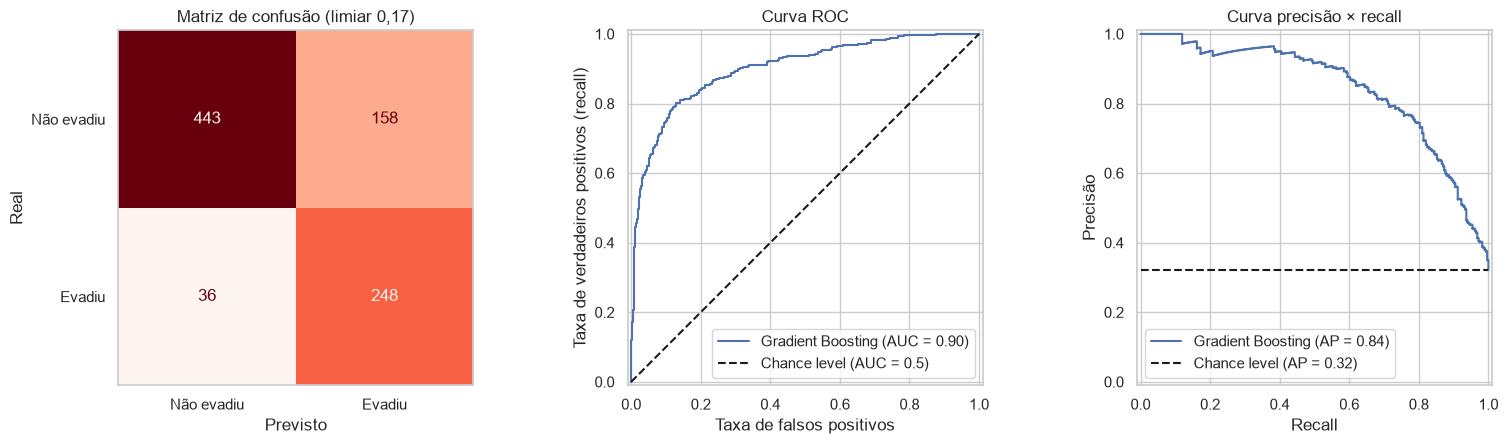

In [8]:
fig, eixos = plt.subplots(1, 3, figsize=(16, 4.6))
ConfusionMatrixDisplay.from_predictions(y_teste, prob_teste >= limiar, display_labels=["Não evadiu", "Evadiu"],
                                        cmap="Reds", colorbar=False, ax=eixos[0])
eixos[0].set_title(f"Matriz de confusão (limiar {limiar:.2f})".replace(".", ","))
eixos[0].set_xlabel("Previsto")
eixos[0].set_ylabel("Real")
eixos[0].grid(False)
RocCurveDisplay.from_predictions(y_teste, prob_teste, ax=eixos[1], name="Gradient Boosting",
                                 plot_chance_level=True)
eixos[1].set_title("Curva ROC")
eixos[1].set_xlabel("Taxa de falsos positivos")
eixos[1].set_ylabel("Taxa de verdadeiros positivos (recall)")
PrecisionRecallDisplay.from_predictions(y_teste, prob_teste, ax=eixos[2], name="Gradient Boosting",
                                        plot_chance_level=True)
eixos[2].set_title("Curva precisão × recall")
eixos[2].set_xlabel("Recall")
eixos[2].set_ylabel("Precisão")
fig.tight_layout()
salvar(fig, "09_avaliacao_teste.png")
plt.show()

**No teste (885 alunos que o modelo nunca viu):**

- **ROC-AUC 0,90 e PR-AUC 0,84**, próximos da validação cruzada (PR-AUC 0,875). Não há sinal de *overfitting*.
- Dos **284 alunos que evadiram**, o modelo sinalizou **248: recall de 87%**.
- Dos **406 alunos sinalizados**, **248 evadiram de fato: precisão de 61%**. A análise de erros abaixo mostra que boa parte dos 158 falsos alarmes são alunos atrasados no curso.
- Apenas **36 evasões passaram despercebidas**.

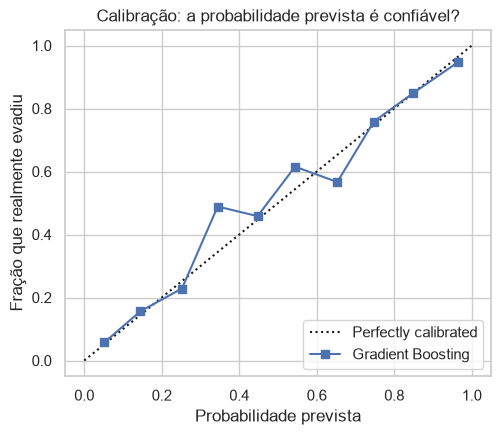

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
CalibrationDisplay.from_predictions(y_teste, prob_teste, n_bins=10, ax=ax, name="Gradient Boosting")
ax.set_title("Calibração: a probabilidade prevista é confiável?")
ax.set_xlabel("Probabilidade prevista")
ax.set_ylabel("Fração que realmente evadiu")
salvar(fig, "10_calibracao.png")
plt.show()

Os pontos ficam perto da diagonal: quando o modelo diz "80% de chance", cerca de 80% desses alunos realmente evadem. Isso acontece porque **não usamos `class_weight`** (que distorce as probabilidades) e tratamos o desbalanceamento só pelo limiar. Por isso o app pode mostrar a probabilidade diretamente ao usuário.

## 6. O que o modelo aprendeu

Usamos **importância por permutação** no teste: embaralhamos uma coluna por vez e medimos quanto a PR-AUC cai. Quanto maior a queda, mais o modelo depende daquela informação. Atributos correlacionados (por exemplo aprovadas e taxa de aprovação) "dividem" a importância entre si.

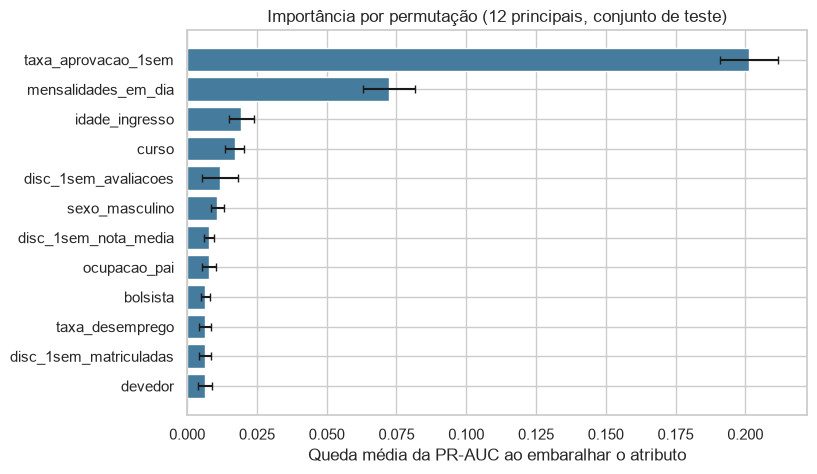

,atributo,queda_pr_auc,dp
13,taxa_aprovacao_1sem,0.201,0.010
18,mensalidades_em_dia,0.072,0.009
3,idade_ingresso,0.019,0.004
24,curso,0.017,0.003
9,disc_1sem_avaliacoes,0.012,0.006
19,sexo_masculino,0.011,0.002
11,disc_1sem_nota_media,0.008,0.002
30,ocupacao_pai,0.008,0.003
20,bolsista,0.006,0.002
4,taxa_desemprego,0.006,0.002


In [10]:
colunas_modelo = todas_colunas_do_cenario(NOME_CENARIO)
importancias = permutation_importance(resultado["pipeline"], teste[colunas_modelo], y_teste,
                                      scoring="average_precision", n_repeats=10, random_state=42, n_jobs=-1)
importancia = (pd.DataFrame({"atributo": colunas_modelo, "queda_pr_auc": importancias.importances_mean,
                             "dp": importancias.importances_std})
                 .sort_values("queda_pr_auc", ascending=False).head(12))
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importancia["atributo"][::-1], importancia["queda_pr_auc"][::-1], xerr=importancia["dp"][::-1],
        color="#457b9d", capsize=3)
ax.set_xlabel("Queda média da PR-AUC ao embaralhar o atributo")
ax.set_title("Importância por permutação (12 principais, conjunto de teste)")
salvar(fig, "11_importancia.png")
plt.show()
importancia.round(4)

A **taxa de aprovação no 1º semestre** domina: embaralhá-la derruba a PR-AUC em 0,20. Depois vêm **mensalidades em dia** (0,07) e, bem atrás, idade, curso, avaliações realizadas e sexo. Indicadores macroeconômicos e escolaridade dos pais contribuem pouco.

O modelo confirma o que a exploração mostrou: **desempenho acadêmico e situação financeira** são os sinais centrais da evasão nesta base.

## 7. Análise de erros

In [11]:
analise = teste.assign(prob=prob_teste, previsto=(prob_teste >= limiar).astype(int))
analise["tipo"] = np.select(
    [(analise.evadiu == 1) & (analise.previsto == 1), (analise.evadiu == 0) & (analise.previsto == 1),
     (analise.evadiu == 1) & (analise.previsto == 0)],
    ["Verdadeiro positivo", "Falso positivo", "Falso negativo"], default="Verdadeiro negativo")
perfil = ["taxa_aprovacao_1sem", "disc_1sem_nota_media", "mensalidades_em_dia", "devedor", "bolsista",
          "idade_ingresso", "prob"]
print("Perfil médio por tipo de acerto/erro:")
display(analise.groupby("tipo")[perfil].mean().round(2))
print("\nSituação real dos falsos positivos:")
display(analise.loc[analise.tipo == "Falso positivo", "situacao"].value_counts().to_frame("alunos"))

Perfil médio por tipo de acerto/erro:


,taxa_aprovacao_1sem,disc_1sem_nota_media,mensalidades_em_dia,devedor,bolsista,idade_ingresso,prob
tipo,,,,,,,
Falso negativo,0.84,12.53,1.00,0.03,0.17,22.92,0.09
Falso positivo,0.56,9.60,0.91,0.12,0.19,23.10,0.39
Verdadeiro negativo,0.94,12.99,1.00,0.04,0.38,21.54,0.07
Verdadeiro positivo,0.32,6.70,0.62,0.25,0.05,26.54,0.74



Situação real dos falsos positivos:


,alunos
situacao,
Matriculado,94
Formado,64


- **Falsos negativos** (evadiram sem ser sinalizados) parecem alunos que vão bem: aprovação de 84%, nota média 12,5 e todos com mensalidades em dia. Provavelmente saíram por motivos que **não estão nos dados**, como troca de curso, emprego, mudança de cidade, saúde ou falta de identificação com o curso. Para capturá-los seriam necessários outros dados, como frequência, uso do ambiente virtual ou questionários de satisfação.
- **Falsos positivos** têm desempenho fraco (aprovação de 56%, nota 9,6), e **94 dos 158 ainda estavam matriculados**, ou seja, atrasados no curso. Para a coordenação esses alunos também precisam de atenção, então grande parte dos "falsos alarmes" ainda é útil.

### 7.1 Os falsos negativos de perto

Os 36 alunos que evadiram sem receber alerta são o erro mais caro. Olhamos um por um para entender quem são e por que o modelo não os pegou.

In [12]:
from src.dados import FORMAS_INGRESSO

fn = analise[analise.tipo == "Falso negativo"].sort_values("prob", ascending=False)
colunas_fn = ["nome_curso", "idade_ingresso", "forma_ingresso", "bolsista", "mensalidades_em_dia",
              "disc_1sem_matriculadas", "disc_1sem_aprovadas", "disc_1sem_nota_media",
              "disc_2sem_matriculadas", "disc_2sem_aprovadas", "prob"]
tabela_fn = fn[colunas_fn].assign(forma_ingresso=fn.forma_ingresso.map(FORMAS_INGRESSO))
tabela_fn.round(2)

,nome_curso,idade_ingresso,forma_ingresso,bolsista,mensalidades_em_dia,disc_1sem_matriculadas,disc_1sem_aprovadas,disc_1sem_nota_media,disc_2sem_matriculadas,disc_2sem_aprovadas,prob
847,Jornalismo e Comunicação,19,1ª fase - contingente geral,0,1,6,3,13.00,6,2,0.17
120,Turismo,22,Transferência,0,1,6,4,11.50,6,2,0.16
238,Gestão (noturno),25,Maiores de 23 anos,0,1,5,4,11.50,5,3,0.15
452,Enfermagem,18,2ª fase - contingente geral,1,1,7,5,13.46,7,7,0.15
444,Design de Animação e Multimídia,18,2ª fase - contingente geral,1,1,0,0,0.00,0,0,0.15
364,Educação Básica,18,1ª fase - contingente geral,0,1,6,6,11.67,6,6,0.14
700,Tecnologias de Produção de Biocombustíveis,34,Mudança de instituição/curso,0,1,12,10,12.00,10,5,0.14
212,Engenharia Informática,18,1ª fase - contingente geral,0,1,5,1,13.00,5,0,0.14
598,Engenharia Informática,20,Diploma de especialização tecnológica,0,1,5,5,16.50,5,5,0.13
142,Serviço Social,19,1ª fase - contingente geral,0,1,6,5,11.57,6,3,0.13


In [13]:
vn = analise[analise.tipo == "Verdadeiro negativo"]
resumo_fn = pd.Series({
    "mensalidades em dia": fn.mensalidades_em_dia.mean(),
    "aprovação >= 80% no 1º semestre": (fn.taxa_aprovacao_1sem >= 0.8).mean(),
    "probabilidade entre 0,10 e o limiar (quase alerta)": (fn.prob >= 0.10).mean(),
    "aprovação caiu mais de 20 p.p. no 2º semestre": (fn.taxa_aprovacao_2sem < fn.taxa_aprovacao_1sem - 0.2).mean(),
    "foram bem nos dois semestres (>= 80%)": ((fn.taxa_aprovacao_1sem >= 0.8) & (fn.taxa_aprovacao_2sem >= 0.8)).mean(),
    "ingresso por maiores de 23, transferência ou mudança de curso": fn.forma_ingresso.isin([7, 39, 42, 43, 44, 51, 53, 57]).mean(),
})
print(f"{len(fn)} falsos negativos\n")
print((resumo_fn * 100).round(0).astype(int).astype(str).add("%").to_string())
print(f"\nAprovação média no 2º semestre: falsos negativos {fn.taxa_aprovacao_2sem.mean():.0%}, "
      f"verdadeiros negativos {vn.taxa_aprovacao_2sem.mean():.0%}")

36 falsos negativos

mensalidades em dia                                              100%
aprovação >= 80% no 1º semestre                                   81%
probabilidade entre 0,10 e o limiar (quase alerta)                39%
aprovação caiu mais de 20 p.p. no 2º semestre                     28%
foram bem nos dois semestres (>= 80%)                             53%
ingresso por maiores de 23, transferência ou mudança de curso     36%

Aprovação média no 2º semestre: falsos negativos 72%, verdadeiros negativos 92%


In [14]:
# Mesmo modelo e hiperparâmetros, agora no cenário "fim do 2º semestre"
from sklearn.model_selection import cross_val_predict

colunas_2sem = todas_colunas_do_cenario("2_semestre")
modelo_2sem = criar_pipeline(NOME_MODELO, "2_semestre")
modelo_2sem.set_params(**{f"modelo__{k}": v for k, v in resultado["melhores_parametros"].items()})
oof_2sem = cross_val_predict(modelo_2sem, treino[colunas_2sem], treino["evadiu"], cv=validacao_cruzada(),
                             method="predict_proba")[:, 1]
limiar_2sem, _ = escolher_limiar(treino["evadiu"].to_numpy(), oof_2sem)
modelo_2sem.fit(treino[colunas_2sem], treino["evadiu"])
prob_2sem_fn = modelo_2sem.predict_proba(fn[colunas_2sem])[:, 1]
print(f"Limiar no 2º semestre: {limiar_2sem:.2f}")
print(f"Falsos negativos que receberiam alerta numa 2ª rodada: {(prob_2sem_fn >= limiar_2sem).sum()} de {len(fn)}")

Limiar no 2º semestre: 0.18
Falsos negativos que receberiam alerta numa 2ª rodada: 11 de 36


**Quem são e por que o modelo errou**

- **Todos os 36 estavam com as mensalidades em dia** e 29 deles (81%) foram aprovados em 80% ou mais das disciplinas do 1º semestre. Como o modelo se apoia principalmente em aprovação e mensalidades, para ele esses alunos são iguais aos que se formam.
- **19 deles (53%) continuaram indo bem também no 2º semestre.** Esses provavelmente saíram por motivos que não estão nos dados: emprego, mudança de cidade, saúde, troca de curso ou de instituição. Nenhum ajuste no modelo resolve isso, só outros dados (frequência, uso do ambiente virtual, questionário de satisfação).
- **14 (39%) ficaram perto do limiar**, com probabilidade entre 0,10 e 0,17. Baixar o limiar pegaria alguns deles, mas aumentaria bastante os falsos positivos.
- **10 (28%) pioraram no 2º semestre**, com a aprovação caindo mais de 20 pontos. Rodando o mesmo modelo no fim do 2º semestre, **11 dos 36 receberiam o alerta**. Por isso sugerimos usar o modelo em **duas rodadas**: no fim do 1º semestre e de novo no fim do 2º.
- **13 (36%) entraram por "maiores de 23 anos", transferência ou mudança de curso.** São alunos que já chegam com outra trajetória e muitas vezes trabalham, então podem sair mesmo indo bem nas disciplinas.
- Um caso curioso: um aluno com **0 disciplinas no 1º semestre** recebeu só 15%. Na base, quem tem 0 disciplinas no 1º semestre evade em 43% dos casos e se forma em 42%, então o modelo fica em dúvida. Esse perfil deveria ser olhado manualmente pela coordenação.

In [15]:
def desempenho_por_grupo(coluna, rotulos):
    linhas = []
    for valor, grupo in analise.groupby(coluna):
        linhas.append({"grupo": rotulos.get(valor, valor), "alunos": len(grupo),
                       "evasão real": grupo.evadiu.mean(),
                       "recall": recall_score(grupo.evadiu, grupo.previsto, zero_division=0),
                       "precisão": precision_score(grupo.evadiu, grupo.previsto, zero_division=0)})
    return pd.DataFrame(linhas)

analise["faixa_idade"] = pd.cut(analise.idade_ingresso, [0, 20, 25, 100], labels=["até 20", "21 a 25", "26 ou mais"])
pd.concat({
    "Sexo": desempenho_por_grupo("sexo_masculino", {0: "Feminino", 1: "Masculino"}),
    "Turno": desempenho_por_grupo("turno_diurno", {0: "Noturno", 1: "Diurno"}),
    "Idade": desempenho_por_grupo("faixa_idade", {}),
}).round(3)

grupo  alunos  evasão real  recall  precisão
Sexo  0    Feminino     567        0.245   0.820     0.564
      1   Masculino     318        0.456   0.924     0.657
Turno 0     Noturno     102        0.402   0.927     0.704
      1      Diurno     783        0.310   0.864     0.597
Idade 0      até 20     498        0.215   0.804     0.489
      1     21 a 25     182        0.319   0.862     0.581
      2  26 ou mais     205        0.580   0.941     0.778

**Equidade entre grupos.** O recall fica entre 80% e 94% em todos os grupos: o modelo encontra a maioria das evasões de homens e mulheres, do diurno e do noturno, de jovens e de mais velhos. A precisão é menor onde a evasão real é menor (mulheres, alunos de até 20 anos). Isso é esperado, porque quando o evento é mais raro no grupo, uma parte maior das sinalizações vira alarme falso.

Como o modelo usa atributos sensíveis (sexo, idade, estado civil), o resultado **deve servir apenas para oferecer apoio**, nunca para restringir o acesso ou punir alunos. Essa distribuição deve ser monitorada no uso real.

## 8. Extra: e se previssemos as 3 classes?

Para justificar a escolha do alvo binário, treinamos o mesmo modelo para prever *evadiu*, *matriculado* e *formado*.

              precision    recall  f1-score   support

      Evadiu      0.802     0.711     0.754       284
     Formado      0.781     0.910     0.840       442
 Matriculado      0.449     0.333     0.383       159

    accuracy                          0.742       885
   macro avg      0.677     0.651     0.659       885
weighted avg      0.728     0.742     0.730       885



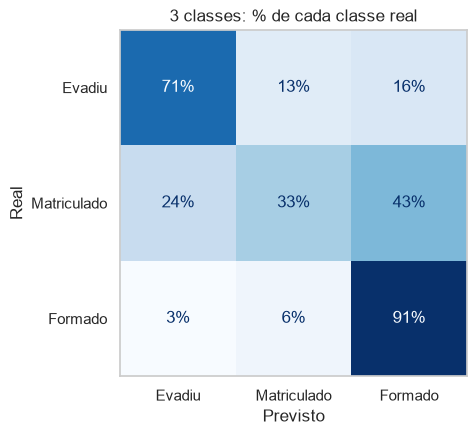

In [16]:
modelo_3_classes = criar_pipeline(NOME_MODELO, NOME_CENARIO)
modelo_3_classes.set_params(**{f"modelo__{k}": v for k, v in resultado["melhores_parametros"].items()})
modelo_3_classes.fit(treino[colunas_modelo], treino["situacao"])
previsto_3 = modelo_3_classes.predict(teste[colunas_modelo])
print(classification_report(teste["situacao"], previsto_3, digits=3))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(teste["situacao"], previsto_3, labels=ORDEM, normalize="true",
                                        values_format=".0%", cmap="Blues", colorbar=False, ax=ax)
ax.set_title("3 classes: % de cada classe real")
ax.set_xlabel("Previsto")
ax.set_ylabel("Real")
ax.grid(False)
salvar(fig, "12_matriz_3_classes.png")
plt.show()

Com 3 classes a acurácia é de 74%, mas a classe **Matriculado** é mal reconhecida: só **33% de recall**, confundida com as outras duas. Faz sentido, porque no fim do 1º semestre um aluno que vai se atrasar se parece tanto com quem vai evadir quanto com quem vai se formar. O recall de *Evadiu* também cai para **71%**, contra 87% no modelo binário com limiar ajustado.

Para a pergunta da coordenação (*quem precisa de apoio?*), o **modelo binário é mais simples e mais útil**.

## 9. Demonstração: prevendo alunos novos

A mesma função usada pelo app (`src/prever.py`) recebe os dados de um aluno e devolve a probabilidade, o nível de risco e os **fatores que mais pesam** para aquele aluno. Os fatores são calculados assim: "se este atributo estivesse no patamar típico de quem não evadiu, quanto o risco cairia?". Abaixo, os três alunos fictícios da pasta `exemplos/`.

In [17]:
artefato = montar_artefato(resultado, treino, NOME_CENARIO, NOME_MODELO)
for arquivo in sorted((RAIZ / "exemplos").glob("*.json")):
    titulo, descricao, aluno = ler_exemplo(arquivo)
    saida = prever_evasao(artefato, aluno)
    print(titulo)
    print(f"  {descricao}")
    print(f"  → probabilidade de evasão {saida['probabilidade_evasao']:.0%} | risco {saida['risco'].upper()}")
    for fator in saida["fatores"]:
        print(f"    • {fator['descricao']}: cairia para {fator['probabilidade_alterada']:.0%}")
    print()

Risco alto: Engenharia Informática, mensalidades atrasadas
  Aluno fictício: Engenharia Informática, ingressou na 2ª fase, mensalidades atrasadas e 1 aprovação em 6 disciplinas no 1º semestre.
  → probabilidade de evasão 97% | risco ALTO
    • com aprovação em 6 de 6 disciplinas no 1º semestre (o típico de quem não evadiu): cairia para 71%
    • com as mensalidades em dia: cairia para 81%
    • com bolsa de estudos: cairia para 94%



Risco baixo: Enfermagem, bolsista, todas aprovadas
  Aluna fictícia: Enfermagem, 1ª fase, bolsista, mensalidades em dia, aprovada em todas as 7 disciplinas.
  → probabilidade de evasão 4% | risco BAIXO

Risco moderado: Gestão noturno, 4 de 6 aprovações
  Aluna fictícia: Gestão (noturno), ingresso por 'maiores de 23 anos', mensalidades em dia, 4 aprovações em 6 disciplinas.
  → probabilidade de evasão 41% | risco MODERADO
    • com aprovação em 6 de 6 disciplinas no 1º semestre (o típico de quem não evadiu): cairia para 9%
    • com bolsa de estudos: cairia para 25%
    • com nota média 12,8 no 1º semestre (típica de quem não evadiu): cairia para 30%



## 10. Conclusões

1. É possível estimar o risco de evasão com boa qualidade: **ROC-AUC 0,90 e PR-AUC 0,84** no teste, identificando **87% dos alunos que evadiram** já no fim do 1º semestre.
2. **Quando prever importa mais do que qual algoritmo usar.** Os três modelos ficaram muito próximos, mas a qualidade sobe bastante com os dados do 1º semestre.
3. **Desempenho acadêmico** (taxa de aprovação) e **situação financeira** (mensalidades) são os sinais mais fortes. Isso aponta para ações concretas: monitoria nas disciplinas iniciais, negociação de mensalidades e oferta de bolsas.
4. **Limitações:**
   - os dados vêm de uma única instituição portuguesa e precisariam de retreino com dados locais para valer em outra realidade, como a brasileira;
   - não se sabe quando "mensalidades em dia" foi medido;
   - evasões por motivos pessoais não aparecem nos dados;
   - o modelo aponta **associações, não causas**: os "e se...?" da demonstração indicam onde olhar, não garantem resultado.

O modelo usado no app é gerado por `python -m src.treinar`, que usa as mesmas funções e sementes deste notebook e chega aos mesmos números.